In [64]:
# Standard libraries
from pathlib import Path
import os
import json
import re

# Data processing
import pandas as pd
import numpy as np
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from pypdf import PdfReader


In [42]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data"

RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
EVALUATION_DIR = DATA_DIR / "evaluation"

CSV_PATH = RAW_DIR / "Resume" / "Resume.csv"
PDF_DIR = RAW_DIR / "data" / "data"

# Create output directories
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
EVALUATION_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("CSV exists:", CSV_PATH.exists())
print("PDF directory exists:", PDF_DIR.exists())

Project root: c:\Users\vishn\OneDrive\Desktop\LLM
CSV exists: True
PDF directory exists: True


In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(CSV_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

display(df.head())

Dataset loaded successfully!
Shape: (2484, 4)

Column names:
['ID', 'Resume_str', 'Resume_html', 'Category']

Data types:
ID             int64
Resume_str       str
Resume_html      str
Category         str
dtype: object


,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR
3,27018550,HR SPECIALIST Summary Dedica...,"<div class=""fontsize fontface vmargins hmargin...",HR
4,17812897,HR MANAGER Skill Highlights ...,"<div class=""fontsize fontface vmargins hmargin...",HR


In [44]:
missing_values = df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage": (
        missing_values / len(df)
    ) * 100
})

display(
    missing_report.sort_values(
        by="Missing_Percentage",
        ascending=False
    )
)


print("Exact duplicate rows:", df.duplicated().sum())

print(
    "Duplicate resume texts:",
    df["Resume_str"].duplicated().sum()
)

,Missing_Count,Missing_Percentage
ID,0,0.0
Resume_str,0,0.0
Resume_html,0,0.0
Category,0,0.0


Exact duplicate rows: 0
Duplicate resume texts: 2


Total categories: 24


Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      120
ADVOCATE                  118
CHEF                      118
FINANCE                   118
ENGINEERING               118
ACCOUNTANT                118
FITNESS                   117
AVIATION                  117
SALES                     116
HEALTHCARE                115
CONSULTANT                115
BANKING                   115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE                63
AUTOMOBILE                 36
BPO                        22
Name: count, dtype: int64

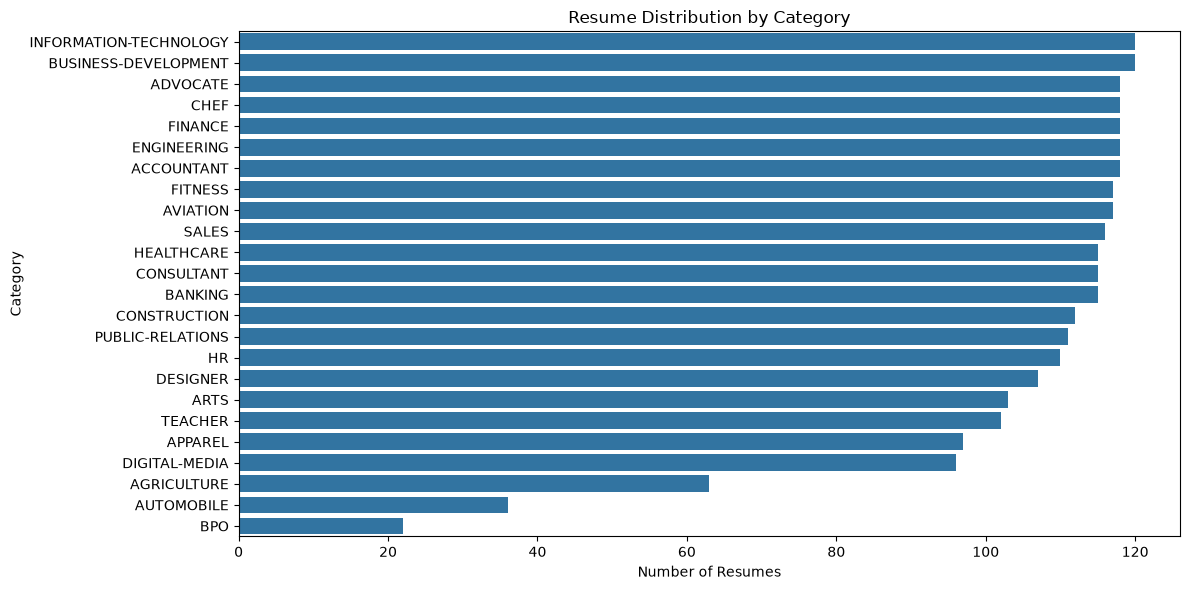

In [45]:
category_counts = df["Category"].value_counts()

print("Total categories:", df["Category"].nunique())

display(category_counts)

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="Category",
    order=category_counts.index
)

plt.title("Resume Distribution by Category")
plt.xlabel("Number of Resumes")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

,char_count,word_count
count,2484.000000,2484.000000
mean,6295.308776,811.325684
std,2769.251458,371.006906
min,21.000000,0.000000
25%,5160.000000,651.000000
50%,5886.500000,757.000000
75%,7227.250000,933.000000
max,38842.000000,5190.000000


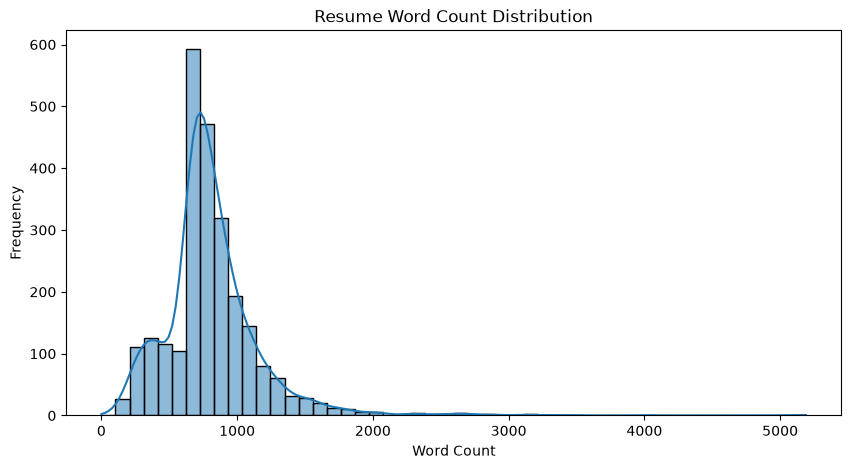

In [46]:
df["char_count"] = df["Resume_str"].fillna("").str.len()

df["word_count"] = (
    df["Resume_str"]
    .fillna("")
    .str.split()
    .str.len()
)

display(
    df[["char_count", "word_count"]].describe()
)


plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="word_count",
    bins=50,
    kde=True
)

plt.title("Resume Word Count Distribution")
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.show()

In [47]:
duplicate_mask = df["Resume_str"].duplicated(keep=False)

duplicate_resumes = df.loc[
    duplicate_mask,
    ["ID", "Category", "Resume_str"]
]

print("Duplicate resume records:", len(duplicate_resumes))

display(
    duplicate_resumes[["ID", "Category"]]
)

Duplicate resume records: 4


,ID,Category
1490,19147603,FINANCE
1509,28398216,FINANCE
2444,16850314,AVIATION
2483,37473139,AVIATION


In [48]:
duplicate_groups = (
    df[df["Resume_str"].duplicated(keep=False)]
    .groupby("Resume_str")
)

for resume_text, group in duplicate_groups:
    print("Number of occurrences:", len(group))
    print("IDs:", group["ID"].tolist())
    print("Categories:", group["Category"].tolist())
    print("-" * 60)

Number of occurrences: 2
IDs: [19147603, 28398216]
Categories: ['FINANCE', 'FINANCE']
------------------------------------------------------------
Number of occurrences: 2
IDs: [16850314, 37473139]
Categories: ['AVIATION', 'AVIATION']
------------------------------------------------------------


In [49]:
empty_resumes = (
    df["Resume_str"]
    .fillna("")
    .str.strip()
    .eq("")
    .sum()
)

short_resumes = (df["word_count"] < 50).sum()

long_resumes = (df["word_count"] > 3000).sum()

print("Empty resumes:", empty_resumes)
print("Resumes below 50 words:", short_resumes)
print("Resumes above 3000 words:", long_resumes)

Empty resumes: 1
Resumes below 50 words: 1
Resumes above 3000 words: 7


In [50]:
# Inspect empty and short resumes
problematic_resumes = df[
    df["word_count"] < 50
]

for _, row in problematic_resumes.iterrows():
    print("ID:", row["ID"])
    print("Category:", row["Category"])
    print("Word count:", row["word_count"])
    print("Resume text:", repr(row["Resume_str"][:500]))
    print("-" * 60)

ID: 12632728
Category: BUSINESS-DEVELOPMENT
Word count: 0
Resume text: '                     '
------------------------------------------------------------


In [51]:
long_resumes = df.nlargest(
    7,
    "word_count"
)

display(
    long_resumes[
        ["ID", "Category", "char_count", "word_count"]
 
    ]
)

,ID,Category,char_count,word_count
2111,11842274,PUBLIC-RELATIONS,35933,5190
1366,14663897,CHEF,38842,5080
2007,39908485,CONSTRUCTION,30055,3994
1817,10554236,ACCOUNTANT,24695,3459
1258,23085604,DIGITAL-MEDIA,24500,3301
1960,17342969,CONSTRUCTION,21675,3128
94,20806155,HR,24834,3119


In [52]:
for index in range(3):
    print(f"\nRecord {index + 1}")

    print("Plain text:")
    print(df.loc[index, "Resume_str"][:300])

    print("\nHTML:")
    print(str(df.loc[index, "Resume_html"])[:500])

    print("=" * 80)


Record 1
Plain text:
         HR ADMINISTRATOR/MARKETING ASSOCIATE

HR ADMINISTRATOR       Summary     Dedicated Customer Service Manager with 15+ years of experience in Hospitality and Customer Service Management.   Respected builder and leader of customer-focused teams; strives to instill a shared, enthusiastic commit

HTML:
<div class="fontsize fontface vmargins hmargins linespacing pagesize" id="document"> <div class="section firstsection" id="SECTION_NAME500375979" style="
      padding-top:0px;
    "> <div class="paragraph PARAGRAPH_NAME firstparagraph" id="PARAGRAPH_500375979_1_326506904" style="
      padding-top:0px;
    "> <div class="name" itemprop="name"> <span class="field fName" id="500375979FNAM1"> </span> <span> </span> <span class="field" id="500375979LNAM1"> HR ADMINISTRATOR/MARKETING ASSOCIATE

HR A

Record 2
Plain text:
         HR SPECIALIST, US HR OPERATIONS       Summary     Versatile  media professional with background in Communications, Marketing, Human Resour

In [53]:
# Work on a copy. Never modify the original raw DataFrame.
clean_df = df.copy()

# Remove empty or whitespace-only resumes
clean_df = clean_df[
    clean_df["Resume_str"].fillna("").str.strip().ne("")
].copy()

# Remove exact duplicate resume texts
clean_df = clean_df.drop_duplicates(
    subset=["Resume_str"],
    keep="first"
).copy()

print("Original records:", len(df))
print("Cleaned records:", len(clean_df))
print("Removed records:", len(df) - len(clean_df))

print("Remaining empty resumes:",
      clean_df["Resume_str"].fillna("").str.strip().eq("").sum())

print("Remaining duplicate texts:",
      clean_df["Resume_str"].duplicated().sum())

Original records: 2484
Cleaned records: 2481
Removed records: 3
Remaining empty resumes: 0
Remaining duplicate texts: 0


In [54]:
CLEANED_PATH = PROCESSED_DIR / "resumes_cleaned.csv"

clean_df.to_csv(CLEANED_PATH, index=False)

print("Saved:", CLEANED_PATH)

Saved: c:\Users\vishn\OneDrive\Desktop\LLM\data\processed\resumes_cleaned.csv


In [55]:
from bs4 import BeautifulSoup
import pandas as pd

def extract_html_text(html):
    if pd.isna(html):
        return ""

    soup = BeautifulSoup(html, "html.parser")

    return soup.get_text(
        separator="\n",
        strip=True
    )

In [56]:
sample = clean_df.head(5).copy()

sample["html_extracted"] = (
    sample["Resume_html"].apply(extract_html_text)
)

for _, row in sample.iterrows():

    print("Resume ID:", row["ID"])

    print("\nOriginal plain text:")
    print(row["Resume_str"][:500])

    print("\nText extracted from HTML:")
    print(row["html_extracted"][:500])

    print("\nPlain text length:", len(row["Resume_str"]))
    print("HTML text length:", len(row["html_extracted"]))

    print("=" * 80)

Resume ID: 16852973

Original plain text:
         HR ADMINISTRATOR/MARKETING ASSOCIATE

HR ADMINISTRATOR       Summary     Dedicated Customer Service Manager with 15+ years of experience in Hospitality and Customer Service Management.   Respected builder and leader of customer-focused teams; strives to instill a shared, enthusiastic commitment to customer service.         Highlights         Focused on customer satisfaction  Team management  Marketing savvy  Conflict resolution techniques     Training and development  Skilled multi-task

Text extracted from HTML:
HR ADMINISTRATOR/MARKETING ASSOCIATE

HR ADMINISTRATOR
Summary
Dedicated Customer Service Manager with 15+ years of experience in Hospitality and Customer Service Management.
Respected builder and leader of customer-focused teams; strives to instill a shared, enthusiastic commitment to customer service.
Highlights
Focused on customer satisfaction
Team management
Marketing savvy
Conflict resolution techniques
Training and devel

In [57]:
clean_df["html_extracted"] = (
    clean_df["Resume_html"].apply(extract_html_text)
)

clean_df["html_word_count"] = (
    clean_df["html_extracted"].str.split().str.len()
)

clean_df["plain_word_count"] = (
    clean_df["Resume_str"].str.split().str.len()
)

print(
    "Empty HTML extractions:",
    clean_df["html_extracted"].str.strip().eq("").sum()
)

print(
    clean_df[
        ["plain_word_count", "html_word_count"]
    ].describe()
)

Empty HTML extractions: 0
       plain_word_count  html_word_count
count       2481.000000      2481.000000
mean         811.770254       811.770254
std          370.849927       370.849927
min          113.000000       113.000000
25%          651.000000       651.000000
50%          757.000000       757.000000
75%          933.000000       933.000000
max         5190.000000      5190.000000


In [58]:
from pathlib import Path
from collections import Counter

PDF_DIR = RAW_DIR / "data" / "data"

pdf_files = list(PDF_DIR.rglob("*.pdf"))

print("Total PDF files:", len(pdf_files))

category_counts = Counter(
    pdf.parent.name for pdf in pdf_files
)

print("\nPDF count by category:")

for category, count in category_counts.most_common():
    print(category, ":", count)

Total PDF files: 2484

PDF count by category:
BUSINESS-DEVELOPMENT : 120
INFORMATION-TECHNOLOGY : 120
ACCOUNTANT : 118
ADVOCATE : 118
CHEF : 118
ENGINEERING : 118
FINANCE : 118
AVIATION : 117
FITNESS : 117
SALES : 116
BANKING : 115
CONSULTANT : 115
HEALTHCARE : 115
CONSTRUCTION : 112
PUBLIC-RELATIONS : 111
HR : 110
DESIGNER : 107
ARTS : 103
TEACHER : 102
APPAREL : 97
DIGITAL-MEDIA : 96
AGRICULTURE : 63
AUTOMOBILE : 36
BPO : 22


In [59]:
import re
from difflib import SequenceMatcher

def normalize_text(text):
    text = str(text).lower()
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"[^\w\s]", "", text)
    return text.strip()


def calculate_similarity(row):
    plain = normalize_text(row["Resume_str"])
    html = normalize_text(row["html_extracted"])

    return SequenceMatcher(
        None,
        plain,
        html
    ).ratio()


clean_df["text_similarity"] = clean_df.apply(
    calculate_similarity,
    axis=1
)

print(clean_df["text_similarity"].describe())

count    2481.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0
Name: text_similarity, dtype: float64


In [60]:
display(
    clean_df.nsmallest(
        10,
        "text_similarity"
    )[
        ["ID", "Category", "text_similarity"]
    ]
)

,ID,Category,text_similarity
0,16852973,HR,1.0
1,22323967,HR,1.0
2,33176873,HR,1.0
3,27018550,HR,1.0
4,17812897,HR,1.0
5,11592605,HR,1.0
6,25824789,HR,1.0
7,15375009,HR,1.0
8,11847784,HR,1.0
9,32896934,HR,1.0


In [66]:
sample_pdf = pdf_files[1]

reader = PdfReader(str(sample_pdf))

extracted_text = "\n".join(
    page.extract_text() or ""
    for page in reader.pages
)

print("PDF:", sample_pdf.name)
print("Category:", sample_pdf.parent.name)
print("Pages:", len(reader.pages))
print("Extracted characters:", len(extracted_text))

print("\nExtracted text:")
print(extracted_text[:1500])

PDF: 10674770.pdf
Category: ACCOUNTANT
Pages: 2
Extracted characters: 7567

Extracted text:
STAFF ACCOUNTANT
Summary
Highly analytical and detail-oriented professional; possessing extensive financial statement background in quality assurance, compliance, auditing,
customer service and regulatory requirements. Thorough knowledge of: financial reporting, cash and accrual basis accounting, fund basis reporting,
GAAP and other accounting standards. Adapt quickly when new software and systems are installed. Proficient with: QuickBooks, MAS, ADP,
Condo Manager, Adobe, and all Microsoft applications software. Excel in problem solving and strategic planning skills.
Highlights
DBA 
Quick Books MAS - Sage Software 
Microsoft Excel ADP Drive 
Microsoft Access Condo Manager 
Microsoft Word
Education
Bachelor of Science
 
: 
Accounting
 
, 
May 2010
 
University of North Carolina
 
ï¼​ 
City
 
, 
State
 
Accounting
Bachelor of Science
 
: 
Business Administration Finance
 
, 
May 2010
 
Business Ad

In [67]:
from pathlib import Path
from pypdf import PdfReader
import pandas as pd
import time

PDF_DIR = RAW_DIR / "data" / "data"

OUTPUT_PATH = PROCESSED_DIR / "pdf_extraction_results.csv"

# Find all PDF files, including uppercase .PDF extensions
pdf_files = [
    path
    for path in PDF_DIR.rglob("*")
    if path.is_file() and path.suffix.lower() == ".pdf"
]

print("Total PDF files:", len(pdf_files))

Total PDF files: 2484


In [68]:
def extract_pdf_text(pdf_path):

    try:
        reader = PdfReader(str(pdf_path), strict=False)

        # Check encryption
        if reader.is_encrypted:
            return {
                "page_count": len(reader.pages),
                "extracted_text": "",
                "char_count": 0,
                "status": "encrypted"
            }

        pages_text = []

        for page in reader.pages:

            text = page.extract_text() or ""

            pages_text.append(text)

        extracted_text = "\n".join(pages_text)

        char_count = len(extracted_text.strip())

        if char_count == 0:
            status = "empty_extraction"

        elif char_count < 100:
            status = "low_text"

        else:
            status = "success"

        return {
            "page_count": len(reader.pages),
            "extracted_text": extracted_text,
            "char_count": char_count,
            "status": status
        }

    except Exception as e:

        return {
            "page_count": 0,
            "extracted_text": "",
            "char_count": 0,
            "status": f"error: {type(e).__name__}: {str(e)[:150]}"
        }

In [69]:
results = []

start_time = time.time()

for index, pdf_path in enumerate(pdf_files, start=1):

    result = extract_pdf_text(pdf_path)

    results.append({
        "filename": pdf_path.name,
        "file_path": str(pdf_path),
        "category": pdf_path.parent.name,
        "page_count": result["page_count"],
        "char_count": result["char_count"],
        "status": result["status"],
        "extracted_text": result["extracted_text"]
    })

    if index % 100 == 0:
        print(f"Processed {index}/{len(pdf_files)} PDFs")

end_time = time.time()

print("\nBatch extraction completed!")
print("Total PDFs:", len(pdf_files))
print("Processing time:", round(end_time - start_time, 2), "seconds")

Processed 100/2484 PDFs
Processed 200/2484 PDFs
Processed 300/2484 PDFs
Processed 400/2484 PDFs
Processed 500/2484 PDFs
Processed 600/2484 PDFs
Processed 700/2484 PDFs
Processed 800/2484 PDFs
Processed 900/2484 PDFs
Processed 1000/2484 PDFs
Processed 1100/2484 PDFs
Processed 1200/2484 PDFs
Processed 1300/2484 PDFs
Processed 1400/2484 PDFs
Processed 1500/2484 PDFs
Processed 1600/2484 PDFs
Processed 1700/2484 PDFs
Processed 1800/2484 PDFs
Processed 1900/2484 PDFs
Processed 2000/2484 PDFs
Processed 2100/2484 PDFs
Processed 2200/2484 PDFs
Processed 2300/2484 PDFs
Processed 2400/2484 PDFs

Batch extraction completed!
Total PDFs: 2484
Processing time: 1645.18 seconds


In [72]:
pdf_results_df = pd.DataFrame(results)

print("Results shape:", pdf_results_df.shape)

display(pdf_results_df.head())
print(pdf_results_df["status"].value_counts())


total = len(pdf_results_df)

successful = (
    pdf_results_df["status"] == "success"
).sum()

failed = total - successful

print("Total PDFs:", total)
print("Successful:", successful)
print("Failed:", failed)

print(
    "Success rate:",
    round((successful / total) * 100, 2),
    "%"
)

Results shape: (2484, 7)


,filename,file_path,category,page_count,char_count,status,extracted_text
0,10554236.pdf,c:\Users\vishn\OneDrive\Desktop\LLM\data\raw\d...,ACCOUNTANT,5,24295,success,ACCOUNTANT\nSummary\nFinancial Accountant spec...
1,10674770.pdf,c:\Users\vishn\OneDrive\Desktop\LLM\data\raw\d...,ACCOUNTANT,2,7567,success,STAFF ACCOUNTANT\nSummary\nHighly analytical a...
2,11163645.pdf,c:\Users\vishn\OneDrive\Desktop\LLM\data\raw\d...,ACCOUNTANT,2,4838,success,ACCOUNTANT\nProfessional Summary\nTo obtain a ...
3,11759079.pdf,c:\Users\vishn\OneDrive\Desktop\LLM\data\raw\d...,ACCOUNTANT,2,5986,success,SENIOR ACCOUNTANT\nExperience\nCompany Name\n ...
4,12065211.pdf,c:\Users\vishn\OneDrive\Desktop\LLM\data\raw\d...,ACCOUNTANT,2,5622,success,SENIOR ACCOUNTANT\nProfessional Summary\nSenio...


status
success             2483
empty_extraction       1
Name: count, dtype: int64
Total PDFs: 2484
Successful: 2483
Failed: 1
Success rate: 99.96 %


In [74]:
failed_pdfs = pdf_results_df[
    pdf_results_df["status"] != "success"
]

display(
    failed_pdfs[
        ["filename", "category", "page_count",
         "char_count", "status"]
    ]
)

from pypdf import PdfReader

failed_path = failed_pdfs.iloc[0]["file_path"]

reader = PdfReader(failed_path, strict=False)

print("Pages:", len(reader.pages))

for i, page in enumerate(reader.pages):
    text = page.extract_text() or ""
    print(f"Page {i+1}: {len(text)} characters")

,filename,category,page_count,char_count,status
802,12632728.pdf,BUSINESS-DEVELOPMENT,1,0,empty_extraction


Pages: 1
Page 1: 0 characters


In [75]:
OUTPUT_PATH = PROCESSED_DIR / "pdf_extraction_results.csv"

pdf_results_df.to_csv(
    OUTPUT_PATH,
    index=False,
    encoding="utf-8"
)

In [76]:
from pypdf import PdfReader

failed_path = failed_pdfs.iloc[0]["file_path"]

reader = PdfReader(failed_path, strict=False)

print("Metadata:", reader.metadata)
print("Page count:", len(reader.pages))

page = reader.pages[0]

print("Page dimensions:", page.mediabox)
print("Extracted text:", repr(page.extract_text()))
print("Images:", len(page.images))

Metadata: {'/Title': '', '/Creator': 'wkhtmltopdf 0.12.4', '/Producer': 'Qt 4.8.7', '/CreationDate': "D:20210808153702+05'30'"}
Page count: 1
Page dimensions: RectangleObject([0, 0, 595, 842])
Extracted text: ''
Images: 0


In [77]:
successful_pdfs = pdf_results_df[
    pdf_results_df["status"] == "success"
]

sample = successful_pdfs.iloc[0]

print("Filename:", sample["filename"])
print("Category:", sample["category"])
print("Pages:", sample["page_count"])

print("\nExtracted resume:\n")
print(sample["extracted_text"])

Filename: 10554236.pdf
Category: ACCOUNTANT
Pages: 5

Extracted resume:

ACCOUNTANT
Summary
Financial Accountant specializing in financial planning, reporting and analysis within the Department of Defense.
Highlights
Account reconciliations
Results-oriented
Financial reporting
Critical thinking
Accounting operations professional
Analysis of financial systems
ERP (Enterprise Resource Planning) software.
Excellent facilitator
Accomplishments
Served on a tiger team which identified and resolved General Ledger postings in DEAMS totaling $360B in accounting adjustments. This allowed
for the first successful fiscal year-end close for 2012.
In collaboration with DFAS Europe, developed an automated tool that identified duplicate obligations. This tool allowed HQ USAFE to
deobligate over $5M in duplicate obligations.
Experience
Company Name
 
July 2011
 
to 
November 2012
 
Accountant
 
City
 
, 
State
Enterprise Resource Planning Office (ERO)
In this position as an Accountant assigned to the D

In [78]:
sample_categories = (
    successful_pdfs["category"]
    .drop_duplicates()
    .head(5)
    .tolist()
)

for category in sample_categories:

    sample = successful_pdfs[
        successful_pdfs["category"] == category
    ].iloc[0]

    print("\n" + "=" * 70)
    print("CATEGORY:", category)
    print("FILENAME:", sample["filename"])
    print("PAGES:", sample["page_count"])
    print("CHARACTERS:", sample["char_count"])
    print("=" * 70)

    print(sample["extracted_text"][:1500])


CATEGORY: ACCOUNTANT
FILENAME: 10554236.pdf
PAGES: 5
CHARACTERS: 24295
ACCOUNTANT
Summary
Financial Accountant specializing in financial planning, reporting and analysis within the Department of Defense.
Highlights
Account reconciliations
Results-oriented
Financial reporting
Critical thinking
Accounting operations professional
Analysis of financial systems
ERP (Enterprise Resource Planning) software.
Excellent facilitator
Accomplishments
Served on a tiger team which identified and resolved General Ledger postings in DEAMS totaling $360B in accounting adjustments. This allowed
for the first successful fiscal year-end close for 2012.
In collaboration with DFAS Europe, developed an automated tool that identified duplicate obligations. This tool allowed HQ USAFE to
deobligate over $5M in duplicate obligations.
Experience
Company Name
 
July 2011
 
to 
November 2012
 
Accountant
 
City
 
, 
State
Enterprise Resource Planning Office (ERO)
In this position as an Accountant assigned to the De

In [82]:
# Get five different categories
sample_categories = sorted(
    successful_pdfs["category"].dropna().unique()
)[:5]

print("Selected categories:", sample_categories)
print("Number of categories:", len(sample_categories))

# Inspect one PDF from each category
for category in sample_categories:

    sample = successful_pdfs[
        successful_pdfs["category"] == category
    ].iloc[0]

    print("\n" + "=" * 70)
    print("CATEGORY:", category)
    print("FILENAME:", sample["filename"])
    print("PAGES:", sample["page_count"])
    print("CHARACTERS:", sample["char_count"])
    print("=" * 70)

    print(sample["extracted_text"][:1000])

Selected categories: ['ACCOUNTANT', 'ADVOCATE', 'AGRICULTURE', 'APPAREL', 'ARTS']
Number of categories: 5

CATEGORY: ACCOUNTANT
FILENAME: 10554236.pdf
PAGES: 5
CHARACTERS: 24295
ACCOUNTANT
Summary
Financial Accountant specializing in financial planning, reporting and analysis within the Department of Defense.
Highlights
Account reconciliations
Results-oriented
Financial reporting
Critical thinking
Accounting operations professional
Analysis of financial systems
ERP (Enterprise Resource Planning) software.
Excellent facilitator
Accomplishments
Served on a tiger team which identified and resolved General Ledger postings in DEAMS totaling $360B in accounting adjustments. This allowed
for the first successful fiscal year-end close for 2012.
In collaboration with DFAS Europe, developed an automated tool that identified duplicate obligations. This tool allowed HQ USAFE to
deobligate over $5M in duplicate obligations.
Experience
Company Name
 
July 2011
 
to 
November 2012
 
Accountant
 
City

In [84]:
import re
import html

all_text = (
    successful_pdfs["extracted_text"]
    .fillna("")
    .astype(str)
)

# Count HTML entities
html_entity_count = all_text.str.count(
    r"&(?:#\d+|#x[0-9A-Fa-f]+|[A-Za-z]+);"
).sum()

# Count suspicious encoding characters
suspicious_chars = ["Â", "Ã", "ï", "�"]

encoding_count = sum(
    all_text.str.count(re.escape(char)).sum()
    for char in suspicious_chars
)

# Count repeated spaces and tabs
multiple_spaces = all_text.str.count(
    r"[ \t]{2,}"
).sum()

print("HTML entities:", html_entity_count)
print("Potential encoding artifacts:", encoding_count)
print("Repeated spaces/tabs:", multiple_spaces)

HTML entities: 24
Potential encoding artifacts: 17046
Repeated spaces/tabs: 1474


In [86]:
suspicious_chars = ["Â", "Ã", "ï", "�"]

for char in suspicious_chars:

    count = all_text.str.count(
        re.escape(char)
    ).sum()

    print(repr(char), ":", count)


for char in suspicious_chars:

    mask = all_text.str.contains(
        re.escape(char),
        na=False
    )

    print("\nCharacter:", repr(char))
    print("Affected resumes:", mask.sum())

    examples = all_text[mask].head(3)

    for text in examples:
        position = text.find(char)
        print(text[max(0, position-40):position+60])

'Â' : 9738
'Ã' : 365
'ï' : 6943
'�' : 0

Character: 'Â'
Affected resumes: 955
rant/CMS
Excel
QuickBooks Pro
SQL
AccessÂ 
Peachtree
Hyperion
Financial reporting
US GAAP principles

 
, 
State
Accounting for six companiesÂ 
Maintained confidential information, such as pay rates, b
on
Supervised team of two staff members.Â 
Professional Summary
Detail-oriented Accountant with 5 ye

Character: 'Ã'
Affected resumes: 102
 
State
 
Accountant
Reviewed accountantÃ†s book entries to ensure accuracy of the G/L. 
Responsible
g, Administrative Manager,
Entrees, EntrÃ©es, Hr, Microsoft Office, Ms Office, Purchase Orders
ue for multiple entities (Bookstore, CafÃ©, Coffee Shop) at each 
location
Provide monthly financial

Character: 'ï'
Affected resumes: 1187
y 2010
 
University of North Carolina
 
ï¼​ 
City
 
, 
State
 
Accounting
Bachelor of Science
 
: 
B
11
 
to 
November 2015
 
Company Name
 
ï¼​ 
City
 
, 
State
Processed accounts receivables payments
Aug 2015
 
to 
Current
 
Company Name
 
ï¼​

In [89]:
test_texts = [
    "CafÃ©",
    "EntrÃ©es",
    "Accounting for six companiesÂ",
    "Designed Â weekly lesson plans",
    "ï¼​"
]

for text in test_texts:

    print("\nOriginal:", repr(text))

    try:
        # Remove zero-width spaces only for this diagnostic test
        test = text.replace("\u200b", "")

        repaired = test.encode(
            "latin-1"
        ).decode("utf-8")

        print("Repaired:", repr(repaired))

    except UnicodeError as e:
        print("Cannot repair:", e)


Original: 'CafÃ©'
Repaired: 'Café'

Original: 'EntrÃ©es'
Repaired: 'Entrées'

Original: 'Accounting for six companiesÂ'
Cannot repair: 'utf-8' codec can't decode byte 0xc2 in position 28: unexpected end of data

Original: 'Designed Â weekly lesson plans'
Cannot repair: 'utf-8' codec can't decode byte 0xc2 in position 9: invalid continuation byte

Original: 'ï¼\u200b'
Cannot repair: 'utf-8' codec can't decode bytes in position 0-1: unexpected end of data


In [91]:
import re
import html
import unicodedata

def clean_resume_text(text):

    if not isinstance(text, str):
        return ""

    # 1. Decode HTML entities
    text = html.unescape(text)

    # 2. Remove zero-width formatting characters
    text = text.replace("\u200b", "")
    text = text.replace("\ufeff", "")

    # 3. Normalize Unicode representation
    text = unicodedata.normalize("NFC", text)

    # 4. Normalize spaces and tabs without removing newlines
    text = re.sub(r"[ \t]+", " ", text)

    # 5. Remove spaces around line breaks
    text = re.sub(r" *\n *", "\n", text)

    # 6. Remove excessive blank lines
    text = re.sub(r"\n{3,}", "\n\n", text)

    return text.strip()

In [92]:
test_text = """
Accounting for six companiesÂ
Skills     Python    Java
Designed weekly lesson plans&#x20;
"""

cleaned_test = clean_resume_text(test_text)

print("Original:")
print(repr(test_text))

print("\nCleaned:")
print(repr(cleaned_test))

Original:
'\nAccounting for six companiesÂ\nSkills     Python    Java\nDesigned weekly lesson plans&#x20;\n'

Cleaned:
'Accounting for six companiesÂ\nSkills Python Java\nDesigned weekly lesson plans'


In [93]:
pdf_results_df["cleaned_text"] = (
    pdf_results_df["extracted_text"]
    .apply(clean_resume_text)
)

In [94]:
empty_after_cleaning = (
    pdf_results_df["cleaned_text"]
    .str.strip()
    .eq("")
)

print("Empty after cleaning:", empty_after_cleaning.sum())

Empty after cleaning: 1


In [95]:
pdf_results_df["original_char_count"] = (
    pdf_results_df["extracted_text"].str.len()
)

pdf_results_df["cleaned_char_count"] = (
    pdf_results_df["cleaned_text"].str.len()
)

display(
    pdf_results_df[
        ["filename", "original_char_count", "cleaned_char_count"]
    ].head(10)
)

,filename,original_char_count,cleaned_char_count
0,10554236.pdf,24295,24210
1,10674770.pdf,7567,7511
2,11163645.pdf,4838,4769
3,11759079.pdf,5986,5943
4,12065211.pdf,5622,5584
5,12202337.pdf,5301,5256
6,12338274.pdf,5959,5874
7,12442909.pdf,4884,4841
8,12780508.pdf,7545,7498
9,12802330.pdf,6464,6426


In [96]:
sample = pdf_results_df[
    pdf_results_df["status"] == "success"
].iloc[0]

print(sample["cleaned_text"][:2000])

ACCOUNTANT
Summary
Financial Accountant specializing in financial planning, reporting and analysis within the Department of Defense.
Highlights
Account reconciliations
Results-oriented
Financial reporting
Critical thinking
Accounting operations professional
Analysis of financial systems
ERP (Enterprise Resource Planning) software.
Excellent facilitator
Accomplishments
Served on a tiger team which identified and resolved General Ledger postings in DEAMS totaling $360B in accounting adjustments. This allowed
for the first successful fiscal year-end close for 2012.
In collaboration with DFAS Europe, developed an automated tool that identified duplicate obligations. This tool allowed HQ USAFE to
deobligate over $5M in duplicate obligations.
Experience
Company Name

July 2011

to
November 2012

Accountant

City

,
State
Enterprise Resource Planning Office (ERO)
In this position as an Accountant assigned to the Defense Enterprise Accounting and Management System (DEAMS) ERO I was
responsible

In [97]:
sample_text = pdf_results_df.loc[
    pdf_results_df["filename"] == "10554236.pdf",
    "cleaned_text"
].iloc[0]

print("Remaining HTML entities:")

matches = re.findall(
    r"&(?:#\d+|#x[0-9A-Fa-f]+|[A-Za-z]+);",
    sample_text
)

print(matches[:20])
print("Total remaining:", len(matches))

Remaining HTML entities:
[]
Total remaining: 0


In [98]:
original_text = pdf_results_df.loc[
    pdf_results_df["filename"] == "10554236.pdf",
    "extracted_text"
].iloc[0]

print("Original:", original_text.count("&#x20;"))
print("Cleaned:", sample_text.count("&#x20;"))

Original: 0
Cleaned: 0


In [99]:
entity_pattern = (
    r"&(?:#\d+|#x[0-9A-Fa-f]+|[A-Za-z]+);"
)

remaining_entities = (
    pdf_results_df["cleaned_text"]
    .fillna("")
    .str.count(entity_pattern)
)

print("Remaining HTML entities:", remaining_entities.sum())

print(
    "PDFs containing HTML entities:",
    (remaining_entities > 0).sum()
)

Remaining HTML entities: 4
PDFs containing HTML entities: 4


In [100]:
for char in ["Â", "Ã", "ï", "�"]:

    count = (
        pdf_results_df["cleaned_text"]
        .fillna("")
        .str.count(re.escape(char))
        .sum()
    )

    print(repr(char), ":", count)

'Â' : 9738
'Ã' : 365
'ï' : 6943
'�' : 0


In [101]:
entity_pattern = (
    r"&(?:#\d+|#x[0-9A-Fa-f]+|[A-Za-z]+);"
)

for _, row in pdf_results_df.iterrows():

    text = row["cleaned_text"] or ""

    matches = re.findall(entity_pattern, text)

    if matches:
        print("\nFilename:", row["filename"])
        print("Category:", row["category"])
        print("Entities:", matches)


Filename: 15856762.pdf
Category: BANKING
Entities: ['&I;']

Filename: 17025292.pdf
Category: CONSULTANT
Entities: ['&T;']

Filename: 23063986.pdf
Category: FITNESS
Entities: ['&Tourism;']

Filename: 27624540.pdf
Category: SALES
Entities: ['&S;']


In [102]:
for _, row in pdf_results_df.iterrows():

    text = row["cleaned_text"] or ""

    matches = list(
        re.finditer(entity_pattern, text)
    )

    for match in matches:

        start = max(0, match.start() - 80)
        end = min(len(text), match.end() + 80)

        print("\nFilename:", row["filename"])
        print("Category:", row["category"])
        print("Matched text:", match.group())
        print("Context:", repr(text[start:end]))


Filename: 15856762.pdf
Category: BANKING
Matched text: &I;
Context: "r the Bank's Business Banking Group a $55 million production P/L budget - CRE; C&I; Asset Based Lending and\nSBA.\nManage the Bank's Private Banking (high-net-worth)"

Filename: 17025292.pdf
Category: CONSULTANT
Matched text: &T;
Context: 'ical 3rd party service providers - ACS/Xerox, Cognizant, Avaya, IBM, Verizon, AT&T; Ability to develop detailed\ntechnical instructions and processes; Ability to or'

Filename: 23063986.pdf
Category: FITNESS
Matched text: &Tourism;
Context: "eisure Programming; Leisure & Consumer Culture; Marketing in\nRecreation, Sport, &Tourism; Macroeconomic Principles GPA: 3.61/4.00\nInterests\nIllinois Governor's Conferenc"

Filename: 27624540.pdf
Category: SALES
Matched text: &S;
Context: 'the Special Staff and the Personal Staff to the Commanding General of the AMEDDC&S; principal\nduties included presenting briefings on sensitive issues and providin'


In [103]:
import re
import html

entity_pattern = r"&(?:#\d+|#x[0-9A-Fa-f]+|[A-Za-z][A-Za-z0-9]+);"

def count_decodable_entities(text):
    if not isinstance(text, str):
        return 0

    matches = re.findall(entity_pattern, text)

    return sum(
        html.unescape(match) != match
        for match in matches
    )

remaining = pdf_results_df["cleaned_text"].apply(
    count_decodable_entities
).sum()

print("Remaining recognized HTML entities:", remaining)



Remaining recognized HTML entities: 0


In [104]:
OUTPUT_PATH = PROCESSED_DIR / "pdf_extraction_results.csv"

pdf_results_df.to_csv(
    OUTPUT_PATH,
    index=False,
    encoding="utf-8"
)

print("Saved:", OUTPUT_PATH)
print("Records:", len(pdf_results_df))

Saved: c:\Users\vishn\OneDrive\Desktop\LLM\data\processed\pdf_extraction_results.csv
Records: 2484


In [105]:
csv_ids = set(
    df["ID"].astype(str).str.replace(r"\.0$", "", regex=True)
)

pdf_ids = set(
    pdf_results_df["filename"].str.replace(
        r"\.pdf$", "", regex=True
    )
)

print("CSV unique IDs:", len(csv_ids))
print("PDF unique IDs:", len(pdf_ids))
print("Matching IDs:", len(csv_ids & pdf_ids))
print("CSV IDs without PDFs:", len(csv_ids - pdf_ids))
print("PDF IDs without CSV records:", len(pdf_ids - csv_ids))

CSV unique IDs: 2484
PDF unique IDs: 2484
Matching IDs: 2484
CSV IDs without PDFs: 0
PDF IDs without CSV records: 0


In [106]:
# Create PDF ID from filename
pdf_results_df["ID"] = (
    pdf_results_df["filename"]
    .str.replace(".pdf", "", regex=False)
)

# Convert IDs to a consistent type
df["ID"] = df["ID"].astype(str).str.replace(
    r"\.0$", "", regex=True
)

pdf_results_df["ID"] = pdf_results_df["ID"].astype(str)

# Merge CSV and PDF datasets
comparison_df = df.merge(
    pdf_results_df[["ID", "cleaned_text", "status"]],
    on="ID",
    how="inner",
    validate="one_to_one"
)

print("Comparison dataset shape:", comparison_df.shape)

display(
    comparison_df[
        ["ID", "Category", "Resume_str", "cleaned_text"]
    ].head()
)

Comparison dataset shape: (2484, 8)


,ID,Category,Resume_str,cleaned_text
0,16852973,HR,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,HR ADMINISTRATOR/MARKETING ASSOCIATE HR ADMINI...
1,22323967,HR,"HR SPECIALIST, US HR OPERATIONS ...","HR SPECIALIST, US HR OPERATIONS\nSummary\nVers..."
2,33176873,HR,HR DIRECTOR Summary Over 2...,HR DIRECTOR\nSummary\nOver 20 years experience...
3,27018550,HR,HR SPECIALIST Summary Dedica...,"HR SPECIALIST\nSummary\nDedicated, Driven, and..."
4,17812897,HR,HR MANAGER Skill Highlights ...,HR MANAGER\nSkill Highlights\nHR SKILLS\nHR De...


In [107]:
import re

def normalize_text(text):

    text = str(text).lower()

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text)

    # Remove punctuation, preserving letters and numbers
    text = re.sub(r"[^\w\s]", "", text)

    return text.strip()

In [110]:
from difflib import SequenceMatcher

def calculate_similarity(row):

    csv_text = normalize_text(row["Resume_str"])
    pdf_text = normalize_text(row["cleaned_text"])

    if not csv_text or not pdf_text:
        return 0.0

    return SequenceMatcher(
        None,
        csv_text,
        pdf_text
    ).ratio()


comparison_df["similarity"] = comparison_df.apply(
    calculate_similarity,
    axis=1
)

print(
    comparison_df["similarity"].describe()
)


exact_matches = (
    comparison_df["similarity"] == 1.0
).sum()

print("Total records:", len(comparison_df))
print("Exact matches:", exact_matches)
print("Non-exact matches:", len(comparison_df) - exact_matches)

count    2484.000000
mean        0.993727
std         0.028353
min         0.000000
25%         0.996887
50%         0.998990
75%         0.999789
max         1.000000
Name: similarity, dtype: float64
Total records: 2484
Exact matches: 424
Non-exact matches: 2060


In [111]:
def categorize_similarity(score):

    if score == 1.0:
        return "Exact Match"

    elif score >= 0.90:
        return "High Similarity"

    elif score >= 0.70:
        return "Moderate Similarity"

    else:
        return "Low Similarity"


comparison_df["similarity_category"] = (
    comparison_df["similarity"]
    .apply(categorize_similarity)
)

print(
    comparison_df["similarity_category"].value_counts()
)



mismatched = comparison_df[
    comparison_df["similarity"] < 1.0
].sort_values("similarity")

display(
    mismatched[
        ["ID", "Category", "similarity",
         "Resume_str", "cleaned_text"]
    ].head(5)
)

similarity_category
High Similarity        2044
Exact Match             424
Moderate Similarity      13
Low Similarity            3
Name: count, dtype: int64


,ID,Category,similarity,Resume_str,cleaned_text
656,12632728,BUSINESS-DEVELOPMENT,0.000000,,
1366,14663897,CHEF,0.457469,CHEF Credentials National R...,CHEF\nCredentials\nNational Registry of Food S...
2265,12386670,ARTS,0.601635,ARTS INSTRUCTOR Summary Moti...,ARTS INSTRUCTOR\nSummary\nMotivated teaching p...
906,23477199,FITNESS,0.773676,R&D NEW PRODUCT DEVELOPMENT TECHNICIA...,R&D NEW PRODUCT DEVELOPMENT TECHNICIAN\nExperi...
1657,15746146,APPAREL,0.781015,MEN'S SR DESIGNER - FREELANCE ...,MEN'S SR DESIGNER - FREELANCE\nSummary\nInnova...


In [112]:
# Exclude records where both sources have empty text
comparison_df["csv_normalized"] = (
    comparison_df["Resume_str"].apply(normalize_text)
)

comparison_df["pdf_normalized"] = (
    comparison_df["cleaned_text"].apply(normalize_text)
)

# Identify empty records
comparison_df["is_empty"] = (
    comparison_df["csv_normalized"].eq("") &
    comparison_df["pdf_normalized"].eq("")
)

# Get records with similarity below 0.90
mismatch_df = comparison_df[
    (comparison_df["similarity"] < 0.90) &
    (~comparison_df["is_empty"])
].copy()

print("Records requiring investigation:", len(mismatch_df))

display(
    mismatch_df[
        [
            "ID",
            "Category",
            "similarity",
            "status"
        ]
    ].sort_values("similarity")
)

Records requiring investigation: 15


,ID,Category,similarity,status
1366,14663897,CHEF,0.457469,success
2265,12386670,ARTS,0.601635,success
906,23477199,FITNESS,0.773676,success
1657,15746146,APPAREL,0.781015,success
2267,15306049,ARTS,0.831454,success
451,12171093,ADVOCATE,0.835116,success
1978,29894080,CONSTRUCTION,0.866860,success
1295,20490741,DIGITAL-MEDIA,0.871037,success
1933,26509539,CONSTRUCTION,0.873235,success
2463,29595906,AVIATION,0.874903,success


In [113]:
mismatch_df["csv_length"] = (
    mismatch_df["csv_normalized"].str.len()
)

mismatch_df["pdf_length"] = (
    mismatch_df["pdf_normalized"].str.len()
)

mismatch_df["length_difference"] = (
    mismatch_df["csv_length"] -
    mismatch_df["pdf_length"]
)

display(
    mismatch_df[
        [
            "ID",
            "similarity",
            "csv_length",
            "pdf_length",
            "length_difference"
        ]
    ].sort_values("similarity")
)

,ID,similarity,csv_length,pdf_length,length_difference
1366,14663897,0.457469,34365,10250,24115
2265,12386670,0.601635,6421,6424,-3
906,23477199,0.773676,6607,6613,-6
1657,15746146,0.781015,7263,4683,2580
2267,15306049,0.831454,1680,1779,-99
451,12171093,0.835116,3061,3204,-143
1978,29894080,0.866860,8305,8279,26
1295,20490741,0.871037,11955,12207,-252
1933,26509539,0.873235,6650,5317,1333
2463,29595906,0.874903,1286,1304,-18


In [114]:
from difflib import unified_diff

inspect_ids = [
    "14663897",
    "12386670",
    "15746146",
    "23477199"
]

for resume_id in inspect_ids:

    row = comparison_df[
        comparison_df["ID"] == resume_id
    ].iloc[0]

    csv_text = row["csv_normalized"]
    pdf_text = row["pdf_normalized"]

    print("\n" + "=" * 80)
    print("ID:", resume_id)
    print("Category:", row["Category"])
    print("Similarity:", row["similarity"])
    print("CSV length:", len(csv_text))
    print("PDF length:", len(pdf_text))

    print("\nCSV TEXT (first 1000 characters):")
    print(csv_text[:1000])

    print("\nPDF TEXT (first 1000 characters):")
    print(pdf_text[:1000])

    print("\n" + "-" * 80)


ID: 14663897
Category: CHEF
Similarity: 0.45746946094362884
CSV length: 34365
PDF length: 10250

CSV TEXT (first 1000 characters):
chef credentials national registry of food safety professionals certified food safety manager national registry of food safety professionals test administratorproctor education and training high school diploma jun 1991 newington high school  city  state summary passionate chef with broad background in various culinary styles and positions a natural leader with excellent interpersonal communication skills and the ability to get things done overcoming any obstacles accomplishments voted best restaurant 2013 multiple best of accolades experience chef oct 2016 to current company name  city  state all aspects of an independently operated hospital kitchen including staffing payroll menus inventoryordering pl employee training and discipline cleaning and equipment maintenance monitor pl and food and labor costs to maximize budget and minimize waste interview hire

In [118]:
from pypdf import PdfReader

pdf_path = r"C:\Users\vishn\OneDrive\Desktop\LLM\data\raw\data\data\CHEF\14663897.pdf"

reader = PdfReader(pdf_path)

print("Total pages:", len(reader.pages))

total_chars = 0

for page_number, page in enumerate(reader.pages, start=1):

    page_text = page.extract_text() or ""
    total_chars += len(page_text)

    print(f"\n{'=' * 60}")
    print(f"PAGE {page_number}")
    print("Characters:", len(page_text))

    print("\nSTART:")
    print(repr(page_text[:200]))

    print("\nEND:")
    print(repr(page_text[-200:]))

print("\nTotal extracted characters:", total_chars)

Total pages: 2

PAGE 1
Characters: 4242

START:
'CHEF\nCredentials\nNational Registry of Food Safety Professionals Certified Food Safety Manager\nNational Registry of Food Safety Professionals Test Administrator/Proctor\nEducation and Training\nHigh Scho'

END:
' to ensure that employees follow standards and regulations.\nCheck the quantity and quality of received products.\nOrder or requisition food or other supplies needed to ensure efficient operation.\nCheck'

PAGE 2
Characters: 6337

START:
'Supervise or coordinate activities of cooks or workers engaged in food preparation.\nInspect supplies, equipment, or work areas to ensure conformance to established standards.\nDetermine how food should'

END:
'\nmultiple kitchens or restaurants in an establishment such as a restaurant chain, hospital, or hotel.\nRestaurant / Kitchen & Bar Manager\n \nAug 2009\n \nto \nAug 2012\n \nCompany Name\n \nï¼\u200b \nCity\n \n, \nState'

Total extracted characters: 10579


In [116]:
resume_id = "12386670"

row = comparison_df[
    comparison_df["ID"] == resume_id
].iloc[0]

print("ID:", row["ID"])
print("Category:", row["Category"])

print("\nCSV:")
print(row["Resume_str"][:1500])

print("\nPDF:")
print(row["cleaned_text"][:1500])

ID: 12386670
Category: ARTS

CSV:
         ARTS INSTRUCTOR       Summary    Motivated teaching professional with over 22 years' experience addressing student needs and ensuring proper student development through formative assessments and student-centered innovations in curriculum implementation of art across multiple content fields.      Highlights          Creative lesson planning  Adept classroom manager  Differentiating instruction specialist  Data-driven curriculum expertise      Learning disabilities expertise  Assessment techniques for documented growth  Kind and empathetic  Urban public schools background            Experience      Arts Instructor  ,   08/1990   -   05/2012    Company Name   -   City  ,   State      Planned, implemented, monitored, and assessed a classroom instructional program which was consistent with Tempe and Arizona Board of Education Art standards Taught visual arts, specializing in photography, serigraphy, ceramics, mural painting, mask making, glass mosa

In [119]:
from difflib import SequenceMatcher

resume_id = "14663897"

row = comparison_df[
    comparison_df["ID"] == resume_id
].iloc[0]

csv_text = row["csv_normalized"]
pdf_text = row["pdf_normalized"]

chunk_size = 500

results = []

for start in range(0, len(csv_text), chunk_size):

    chunk = csv_text[start:start + chunk_size]

    similarity = SequenceMatcher(
        None,
        chunk,
        pdf_text
    ).ratio()

    results.append({
        "start_position": start,
        "chunk_length": len(chunk),
        "similarity": similarity,
        "matched": chunk in pdf_text
    })

chunk_df = pd.DataFrame(results)

display(chunk_df)

,start_position,chunk_length,similarity,matched
0,0,500,0.093023,False
1,500,500,0.090791,False
2,1000,500,0.006326,False
3,1500,500,0.003721,True
4,2000,500,0.018047,True
...,...,...,...,...
64,32000,500,0.005023,True
65,32500,500,0.007628,True
66,33000,500,0.044093,True
67,33500,500,0.004465,True


In [120]:
print(
    "Chunks found:",
    chunk_df["matched"].sum()
)

print(
    "Total chunks:",
    len(chunk_df)
)

print(
    "Chunk coverage:",
    round(chunk_df["matched"].mean() * 100, 2),
    "%"
)

Chunks found: 42
Total chunks: 69
Chunk coverage: 60.87 %


In [121]:
%pip install rapidfuzz

   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------------------ --------------------- 0.8/1.7 MB 5.6 MB/s eta 0:00:01
   ------------------------ --------------- 1.0/1.7 MB 3.6 MB/s eta 0:00:01
   ---------------------------------------- 1.7/1.7 MB 2.7 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [122]:
from rapidfuzz import fuzz
import pandas as pd

chunk_results = []

for start in range(0, len(csv_text), 500):

    chunk = csv_text[start:start + 500]

    score = fuzz.partial_ratio(
        chunk,
        pdf_text
    )

    chunk_results.append({
        "start_position": start,
        "chunk_length": len(chunk),
        "partial_similarity": score,
        "matched": score >= 95
    })

chunk_df = pd.DataFrame(chunk_results)

display(chunk_df)

print(
    "Chunks with at least 95% partial similarity:",
    chunk_df["matched"].sum()
)

print(
    "Total chunks:",
    len(chunk_df)
)

print(
    "Approximate chunk coverage:",
    round(chunk_df["matched"].mean() * 100, 2),
    "%"
)

,start_position,chunk_length,partial_similarity,matched
0,0,500,99.400000,True
1,500,500,99.200000,True
2,1000,500,99.800000,True
3,1500,500,100.000000,True
4,2000,500,100.000000,True
...,...,...,...,...
64,32000,500,100.000000,True
65,32500,500,100.000000,True
66,33000,500,100.000000,True
67,33500,500,100.000000,True


Chunks with at least 95% partial similarity: 49
Total chunks: 69
Approximate chunk coverage: 71.01 %


In [123]:
unmatched_chunks = chunk_df[
    chunk_df["partial_similarity"] < 95
].copy()

display(unmatched_chunks)

,start_position,chunk_length,partial_similarity,matched
20,10000,500,62.653899,False
21,10500,500,46.400000,False
22,11000,500,52.400000,False
28,14000,500,64.600000,False
29,14500,500,46.600000,False
30,15000,500,51.000000,False
36,18000,500,65.800000,False
37,18500,500,46.800000,False
38,19000,500,47.800000,False
44,22000,500,68.400000,False


In [124]:
for _, item in unmatched_chunks.iterrows():

    start = int(item["start_position"])
    length = int(item["chunk_length"])

    chunk = csv_text[start:start + length]

    print("\n" + "=" * 80)
    print("Position:", start)
    print("Similarity:", item["partial_similarity"])
    print("\nCSV CHUNK:")
    print(chunk)


Position: 10000
Similarity: 62.653898768809846

CSV CHUNK:
rvise the food preparation or cooking activities of multiple kitchens or restaurants in an establishment such as a restaurant chain hospital or hotel restaurant  kitchen  bar manager aug 2009 to aug 2012 company name  city  state check identification of customers to verify age requirements for purchase of alcohol balance cash receipts attempt to limit problems and liability related to customers excessive drinking by taking steps such as persuading customers to stop drinking or ordering taxis or 

Position: 10500
Similarity: 46.4

CSV CHUNK:
other transportation for intoxicated patrons stock bar with beer wine liquor and related supplies such as ice glassware napkins or straws serve wine and bottled or draft beer take beverage orders from serving staff or directly from patrons clean bars work areas and tables mix ingredients such as liquor soda water sugar and bitters to prepare cocktails and other drinks slice and pit fruit fo

In [125]:
from rapidfuzz import fuzz

pdf_in_csv = fuzz.partial_ratio(
    pdf_text,
    csv_text
)

print("PDF-to-CSV partial similarity:", pdf_in_csv)

PDF-to-CSV partial similarity: 99.89745593046536


In [126]:
from rapidfuzz import fuzz

score = fuzz.ratio(
    pdf_text,
    csv_text
)

print("Full text similarity:", score)

Full text similarity: 45.85453322873473


In [127]:
from difflib import SequenceMatcher

matcher = SequenceMatcher(
    None,
    csv_text,
    pdf_text,
    autojunk=False
)

for block in matcher.get_matching_blocks():
    if block.size > 0:
        print(
            f"CSV position: {block.a}, "
            f"PDF position: {block.b}, "
            f"Length: {block.size}"
        )

CSV position: 0, PDF position: 0, Length: 241
CSV position: 241, PDF position: 243, Length: 226
CSV position: 467, PDF position: 470, Length: 120
CSV position: 587, PDF position: 592, Length: 12
CSV position: 599, PDF position: 606, Length: 636
CSV position: 1235, PDF position: 1243, Length: 2490
CSV position: 3725, PDF position: 3734, Length: 51
CSV position: 3776, PDF position: 3787, Length: 314
CSV position: 4090, PDF position: 4107, Length: 1564
CSV position: 5654, PDF position: 5673, Length: 4563
CSV position: 10217, PDF position: 10238, Length: 12


In [128]:
matching_blocks = matcher.get_matching_blocks()

matched_chars = sum(
    block.size for block in matching_blocks
)

print("CSV length:", len(csv_text))
print("PDF length:", len(pdf_text))
print("Matched characters:", matched_chars)

print(
    "PDF matching coverage:",
    round(matched_chars / len(pdf_text) * 100, 2),
    "%"
)

print(
    "CSV matching coverage:",
    round(matched_chars / len(csv_text) * 100, 2),
    "%"
)

CSV length: 34365
PDF length: 10250
Matched characters: 10229
PDF matching coverage: 99.8 %
CSV matching coverage: 29.77 %


In [130]:
import pandas as pd
from pathlib import Path

# Load cleaned dataset
DATA_PATH = Path("../data/processed/resumes_cleaned.csv")
df = pd.read_csv(DATA_PATH)

required_columns = ["ID", "Resume_str", "Category"]

missing = set(required_columns) - set(df.columns)
if missing:
    raise ValueError(f"Missing columns: {missing}")

# Basic validation
if len(df) < 50:
    raise ValueError("Dataset contains fewer than 50 resumes.")

if df[required_columns].isnull().any().any():
    raise ValueError("Required columns contain missing values.")

# Calculate category counts
category_counts = df["Category"].value_counts()

# Calculate proportional allocation
raw_allocation = category_counts / len(df) * 50

allocation = raw_allocation.apply(int)

# Distribute remaining slots using largest fractional remainders
remaining = 50 - allocation.sum()

remainders = (raw_allocation - allocation).sort_values(
    ascending=False
)

for category in remainders.index:
    if remaining == 0:
        break

    if allocation[category] < category_counts[category]:
        allocation[category] += 1
        remaining -= 1

# Stratified sampling
sample_parts = []

for category, count in allocation.items():
    if count > 0:
        category_data = df[df["Category"] == category]

        selected = category_data.sample(
            n=int(count),
            random_state=42
        )

        sample_parts.append(selected)

sample = (
    pd.concat(sample_parts)
      .sample(frac=1, random_state=42)
      .reset_index(drop=True)
)

# Verify sample size
assert len(sample) == 50
assert sample["ID"].is_unique

# Define candidate schema
fields = [
    "current_title",
    "previous_titles",
    "current_company",
    "previous_companies",
    "years_experience",
    "seniority",
    "primary_domain",
    "industries",
    "core_skills",
    "secondary_skills",
    "tools",
    "leadership_experience",
    "key_achievements",
    "location",
    "summary"
]

# Create annotation template
annotation_df = sample[
    ["ID", "Category", "Resume_str"]
].copy()

for field in fields:
    annotation_df[field] = None

# Save
OUTPUT_PATH = Path("../data/evaluation/resume_annotation_template.csv")
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

annotation_df.to_csv(OUTPUT_PATH, index=False)

print("Evaluation sample created successfully!")
print("Total resumes:", len(annotation_df))
print("Categories represented:", annotation_df["Category"].nunique())
print("Saved to:", OUTPUT_PATH)

Evaluation sample created successfully!
Total resumes: 50
Categories represented: 24
Saved to: ..\data\evaluation\resume_annotation_template.csv


In [132]:
print("Shape:", annotation_df.shape)

print("\nCategory distribution:")
print(annotation_df["Category"].value_counts())

display(annotation_df.head(3))

Shape: (50, 18)

Category distribution:
Category
BUSINESS-DEVELOPMENT      3
ADVOCATE                  3
ACCOUNTANT                3
CHEF                      3
INFORMATION-TECHNOLOGY    3
ENGINEERING               2
ARTS                      2
BANKING                   2
DIGITAL-MEDIA             2
FITNESS                   2
HEALTHCARE                2
CONSTRUCTION              2
FINANCE                   2
DESIGNER                  2
TEACHER                   2
AVIATION                  2
PUBLIC-RELATIONS          2
APPAREL                   2
CONSULTANT                2
HR                        2
SALES                     2
AUTOMOBILE                1
AGRICULTURE               1
BPO                       1
Name: count, dtype: int64


,ID,Category,Resume_str,current_title,previous_titles,current_company,previous_companies,years_experience,seniority,primary_domain,industries,core_skills,secondary_skills,tools,leadership_experience,key_achievements,location,summary
0,17108676,ENGINEERING,MECHANICAL ENGINEERING INTERN ...,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None
1,41950126,ARTS,LANDSCAPE TECHNICIAN Profession...,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None
2,34953092,BANKING,"CORPORATE BANKING ASSISTANT, INTERN ...",None,None,None,None,None,None,None,None,None,None,None,None,None,None,None


In [133]:
resume_id = 17108676

resume = annotation_df.loc[
    annotation_df["ID"] == resume_id,
    "Resume_str"
].iloc[0]

print(resume)

         MECHANICAL ENGINEERING INTERN         Summary    Highly motivated mechanical engineering student (EIT) interested in pursuing an engaging position in the corporate
setting to implement skills honed through years of engineering background. A dedicated student with problem-solving,
leadership, and communication skills along with the capability to build relationships and work in a team-oriented
environment.      Highlights          Proficient in SolidWorks			Linear Control  AutoCAD	Solid Mechanics  Engineering graphics and design		Microsoft Word  Fluid Mechanics		Microsoft PowerPoint  Thermal Analysis					Project management  Heat Transfer			Time management skills  Statics/Dynamics				Written and verbal communication skills  Material Science  Engineering Probability and Statistics Academic, acrylic, AutoCAD, CAD, concept, Engineer-in-Training, estimating, drawing, graphics and design, Laser,  Material Science, Microsoft Excel, Microsoft PowerPoint, Microsoft Word, design process, 

In [134]:
import json

annotation = {
    "current_title": "Mechanical Engineering Intern",
    "previous_titles": [
        "Systems Engineering Intern",
        "Academic Employee (Grader)"
    ],
    "current_company": None,
    "previous_companies": [],
    "years_experience": None,
    "seniority": "junior",
    "primary_domain": "Mechanical Engineering",
    "industries": [
        "Engineering",
        "Biotechnology/Research"
    ],
    "core_skills": [
        "Mechanical Design",
        "CAD",
        "SolidWorks",
        "AutoCAD",
        "Robotics",
        "Energy Analysis",
        "Material Science",
        "Fluid Mechanics",
        "Heat Transfer",
        "Manufacturing",
        "Prototyping",
        "Project Management"
    ],
    "secondary_skills": [
        "Leadership",
        "Teamwork",
        "Communication",
        "Research",
        "Reporting",
        "Time Management",
        "Problem Solving",
        "Academic Mentoring"
    ],
    "tools": [
        "SolidWorks",
        "AutoCAD",
        "Microsoft Excel",
        "Microsoft Word",
        "Microsoft PowerPoint",
        "Gantt Chart",
        "Laser Cutter",
        "Automated Instrumentation"
    ],
    "leadership_experience": True,
    "key_achievements": [
        "Collaborated with a four-person team to build a mobile robot.",
        "Analyzed robot mobility, torque, friction, and energy transfer.",
        "Created CAD drawings and produced an acrylic clock using a laser cutter.",
        "Assisted with prototype assembly, manufacturing, and fabrication.",
        "Supervised approximately 20 kindergarten children as a teaching assistant."
    ],
    "location": None,
    "summary": (
        "Mechanical engineering student and Engineer-in-Training "
        "with experience in mechanical design, CAD, robotics, energy "
        "analysis, and prototyping. Worked on mobile robot development, "
        "CAD-based product design, manufacturing, and research operations. "
        "Demonstrates teamwork, project coordination, leadership, "
        "and communication skills."
    )
}

# Update only the selected resume
resume_id = 17108676

for field, value in annotation.items():
    annotation_df.loc[
        annotation_df["ID"] == resume_id, field
    ] = json.dumps(value) if isinstance(value, (list, dict)) else value

# Save updated annotations
OUTPUT_PATH = Path("../data/evaluation/resume_annotation_template.csv")

annotation_df.to_csv(OUTPUT_PATH, index=False)

print("First resume annotated and saved.")

First resume annotated and saved.


In [135]:
import json
from pathlib import Path

resume_id = 17108676

annotation = {
    "current_title": "Mechanical Engineering Intern",
    "previous_titles": [
        "Systems Engineering Intern",
        "Academic Employee (Grader)"
    ],
    "current_company": None,
    "previous_companies": [],
    "years_experience": None,
    "seniority": "junior",
    "primary_domain": "Mechanical Engineering",
    "industries": ["Engineering", "Biotechnology/Research"],
    "core_skills": [
        "Mechanical Design", "CAD", "Robotics",
        "Energy Analysis", "Material Science",
        "Fluid Mechanics", "Heat Transfer",
        "Manufacturing", "Prototyping", "Project Management"
    ],
    "secondary_skills": [
        "Leadership", "Teamwork", "Communication",
        "Research", "Reporting", "Time Management",
        "Problem Solving", "Academic Mentoring"
    ],
    "tools": [
        "SolidWorks", "AutoCAD", "Microsoft Excel",
        "Microsoft Word", "Microsoft PowerPoint",
        "Gantt Chart", "Laser Cutter",
        "Automated Instrumentation"
    ],
    "leadership_experience": True,
    "key_achievements": [
        "Collaborated with a four-person team to build a mobile robot.",
        "Analyzed robot mobility, torque, friction, and energy transfer.",
        "Created CAD drawings and produced an acrylic clock using a laser cutter.",
        "Assisted with prototype assembly, manufacturing, and fabrication.",
        "Supervised approximately 20 kindergarten children as a teaching assistant."
    ],
    "location": None,
    "summary": (
        "Mechanical engineering student and Engineer-in-Training "
        "with experience in mechanical design, CAD, robotics, energy "
        "analysis, and prototyping. Worked on mobile robot development, "
        "CAD-based product design, manufacturing, and research operations. "
        "Demonstrates teamwork, project coordination, leadership, "
        "and communication skills."
    )
}

# Update the selected record
mask = annotation_df["ID"] == resume_id

if mask.sum() != 1:
    raise ValueError("Expected exactly one matching resume.")

for field, value in annotation.items():
    annotation_df.loc[mask, field] = (
        json.dumps(value, ensure_ascii=False)
        if isinstance(value, list)
        else value
    )

# Save updated annotation file
output_path = Path("../data/evaluation/resume_annotation_template.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

annotation_df.to_csv(output_path, index=False)

print("Annotation saved.")
print("Annotated resumes:", annotation_df["current_title"].notna().sum())

Annotation saved.
Annotated resumes: 1


In [136]:
resume_id = annotation_df.loc[1, "ID"]

resume = annotation_df.loc[
    annotation_df["ID"] == resume_id,
    "Resume_str"
].iloc[0]

print("Resume ID:", resume_id)
print(resume)

Resume ID: 41950126
         LANDSCAPE TECHNICIAN       Professional Profile    Diligent and driven banking professional who has achieved success in a variety of roles with increasing levels of responsibility. An effective communicator and team-builder with strong analytical, management and organizational skills.       Highlights          Analytical  Detail-oriented   Excellent communication skills   Strong work ethic        Risk management expertise  Excellent time management skills  Exceptional customer service  MS Office proficient            Experience     07/2015   -   Current     Company Name   －   City  ,   State    Loss Prevention/ BSA Analyst        

Evaluate current fraud
situations and formulate recommendations to reduce in the future   Use anti-money laundering
(AML) software to review members' activity for money laundering and other
suspicious activity.    Review structuring
reports if software is not functional. Work cases and alerts
generated by software, documenting co

In [137]:
resume_id = 41950126

resume = annotation_df.loc[
    annotation_df["ID"] == resume_id,
    "Resume_str"
].iloc[0]

chunk_size = 2500

for start in range(0, len(resume), chunk_size):
    print(f"\n--- CHUNK {start // chunk_size + 1} ---\n")
    print(resume[start:start + chunk_size])


--- CHUNK 1 ---

         LANDSCAPE TECHNICIAN       Professional Profile    Diligent and driven banking professional who has achieved success in a variety of roles with increasing levels of responsibility. An effective communicator and team-builder with strong analytical, management and organizational skills.       Highlights          Analytical  Detail-oriented   Excellent communication skills   Strong work ethic        Risk management expertise  Excellent time management skills  Exceptional customer service  MS Office proficient            Experience     07/2015   -   Current     Company Name   －   City  ,   State    Loss Prevention/ BSA Analyst        

Evaluate current fraud
situations and formulate recommendations to reduce in the future   Use anti-money laundering
(AML) software to review members' activity for money laundering and other
suspicious activity.    Review structuring
reports if software is not functional. Work cases and alerts
generated by software, documenting conc

In [138]:
import json
from pathlib import Path

resume_id = 41950126

annotation = {
    "current_title": "Loss Prevention / BSA Analyst",
    "previous_titles": [
        "Branch Representative",
        "Operations Supervisor",
        "Senior Operations Associate",
        "Teller Manager"
    ],
    "current_company": None,
    "previous_companies": [],
    "years_experience": None,
    "seniority": "senior",
    "primary_domain": "Banking Operations and Compliance",
    "industries": [
        "Banking",
        "Credit Union",
        "Financial Services"
    ],
    "core_skills": [
        "Banking Operations",
        "Anti-Money Laundering",
        "BSA Compliance",
        "Fraud Prevention",
        "Fraud Investigation",
        "Risk Management",
        "Regulatory Compliance",
        "Audit Procedures",
        "Operations Management",
        "Team Leadership",
        "Process Improvement",
        "Quality Control",
        "Customer Service",
        "Performance Management"
    ],
    "secondary_skills": [
        "Analytical Skills",
        "Communication",
        "Coaching",
        "Mentoring",
        "Decision Making",
        "Reporting",
        "Time Management",
        "Problem Solving"
    ],
    "tools": [
        "Epysis/Symitar",
        "Meridian Link",
        "STAR Network",
        "Patriot Officer",
        "VISA",
        "Microsoft Office",
        "Anti-Money Laundering Software"
    ],
    "leadership_experience": True,
    "key_achievements": [
        "Led and trained 12 junior team members while maintaining passing audits, 90% customer service, and SLAs for five consecutive years.",
        "Managed a team of 10 branch tellers.",
        "Mentored 18 junior team members.",
        "Balanced daily cash deposits and bank vault inventory with a zero error rate.",
        "Received a regional branch recognition award for outstanding customer service.",
        "Achieved an internal audit score of 90% for five consecutive years.",
        "Received multiple individual corporate recognitions."
    ],
    "location": None,
    "summary": (
        "Experienced banking professional with extensive experience in "
        "banking operations, BSA compliance, anti-money laundering, fraud "
        "prevention, and risk management. Has held roles in branch operations, "
        "financial investigations, and operational supervision. Demonstrates "
        "leadership through managing teams, mentoring employees, maintaining "
        "audit standards, and improving operational performance."
    )
}

mask = annotation_df["ID"] == resume_id

if mask.sum() != 1:
    raise ValueError("Expected exactly one matching resume.")

for field, value in annotation.items():
    annotation_df.loc[mask, field] = (
        json.dumps(value, ensure_ascii=False)
        if isinstance(value, list)
        else value
    )

output_path = Path("../data/evaluation/resume_annotation_template.csv")
annotation_df.to_csv(output_path, index=False)

print("Annotation saved successfully.")
print("Annotated records:", annotation_df["current_title"].notna().sum())

Annotation saved successfully.
Annotated records: 2


In [139]:
from pathlib import Path

# Only select resumes that are not yet annotated
unannotated = annotation_df[
    annotation_df["current_title"].isna()
].copy()

BATCH_SIZE = 5

batch_dir = Path("../data/evaluation/annotation_batches")
batch_dir.mkdir(parents=True, exist_ok=True)

for batch_number, start in enumerate(
    range(0, len(unannotated), BATCH_SIZE), start=1
):
    batch = unannotated.iloc[start:start + BATCH_SIZE]

    output_file = batch_dir / f"batch_{batch_number:02d}.txt"

    with open(output_file, "w", encoding="utf-8") as file:
        for _, row in batch.iterrows():
            file.write(f"\n{'=' * 80}\n")
            file.write(f"RESUME ID: {row['ID']}\n")
            file.write(f"CATEGORY: {row['Category']}\n")
            file.write(f"{'=' * 80}\n\n")
            file.write(str(row["Resume_str"]))
            file.write("\n\n")

    print(f"Created {output_file.name}: {len(batch)} resumes")

print("\nTotal remaining:", len(unannotated))
print("Total batches:", (len(unannotated) + BATCH_SIZE - 1) // BATCH_SIZE)

Created batch_01.txt: 5 resumes
Created batch_02.txt: 5 resumes
Created batch_03.txt: 5 resumes
Created batch_04.txt: 5 resumes
Created batch_05.txt: 5 resumes
Created batch_06.txt: 5 resumes
Created batch_07.txt: 5 resumes
Created batch_08.txt: 5 resumes
Created batch_09.txt: 5 resumes
Created batch_10.txt: 3 resumes

Total remaining: 48
Total batches: 10


In [140]:
from pathlib import Path

batch_path = Path("../data/evaluation/annotation_batches/batch_01.txt")

content = batch_path.read_text(encoding="utf-8")

print(content)


RESUME ID: 34953092
CATEGORY: BANKING

         CORPORATE BANKING ASSISTANT, INTERN           Objective     Dynamic and self-motivated Financial Data Analyst with diverse expertise in programming, mathematics and finance. Has extensive experience of assisting in the development and upgrading of database systems and analytical techniques. A quick learner who can absorb new ideas and can communicate clearly and effectively.       Skills      Programming Language: C/C++, Python, MATLAB, SQL, R, LUA, VBA  Machine Learning: Supervised Learning, Unsupervised Learning, Deep Neural Networks  Finance: Corporate Banking, Financial Forecasting, Financial Analysis  Language: English, Chinese        Experience      Corporate Banking Assistant, Intern    May 2015   to   August 2015     Company Name   －   City  ,   State      Wrote commercial mortgage recommendation reports for risk management, including properties appraisals, cash flow analysis, asset coverage analysis, RAROC analysis and sensitivi

In [141]:
from pathlib import Path

batch_path = Path("../data/evaluation/annotation_batches/batch_01.txt")

content = batch_path.read_text(encoding="utf-8")

print(content)


RESUME ID: 34953092
CATEGORY: BANKING

         CORPORATE BANKING ASSISTANT, INTERN           Objective     Dynamic and self-motivated Financial Data Analyst with diverse expertise in programming, mathematics and finance. Has extensive experience of assisting in the development and upgrading of database systems and analytical techniques. A quick learner who can absorb new ideas and can communicate clearly and effectively.       Skills      Programming Language: C/C++, Python, MATLAB, SQL, R, LUA, VBA  Machine Learning: Supervised Learning, Unsupervised Learning, Deep Neural Networks  Finance: Corporate Banking, Financial Forecasting, Financial Analysis  Language: English, Chinese        Experience      Corporate Banking Assistant, Intern    May 2015   to   August 2015     Company Name   －   City  ,   State      Wrote commercial mortgage recommendation reports for risk management, including properties appraisals, cash flow analysis, asset coverage analysis, RAROC analysis and sensitivi

In [142]:
import json
from pathlib import Path

annotations = {
    34953092: {
        "current_title": "Corporate Banking Assistant Intern",
        "previous_titles": [
            "Office Assistant Intern",
            "Undergraduate Researcher",
            "Assistant Analyst Intern"
        ],
        "current_company": None,
        "previous_companies": [],
        "years_experience": None,
        "seniority": "junior",
        "primary_domain": "Financial Analysis and Banking",
        "industries": [
            "Banking",
            "Financial Services",
            "Research"
        ],
        "core_skills": [
            "Financial Analysis",
            "Corporate Banking",
            "Financial Forecasting",
            "Risk Analysis",
            "Cash Flow Analysis",
            "SQL",
            "Python",
            "Machine Learning",
            "Image Classification",
            "Database Development",
            "Statistical Modeling"
        ],
        "secondary_skills": [
            "Research",
            "Communication",
            "Recommendation Writing",
            "Data Analysis",
            "Problem Solving"
        ],
        "tools": [
            "C/C++", "Python", "MATLAB", "SQL", "R", "LUA", "VBA"
        ],
        "leadership_experience": True,
        "key_achievements": [
            "Developed a customer feedback system using VBA, improving team efficiency by 20%.",
            "Created image classification solutions that improved image processing speed by 30%.",
            "Developed an Updatable Documentation Notification System for commercial loan information management.",
            "Researched SMEs using SQL to support financial product recommendations."
        ],
        "location": None,
        "summary": (
            "Financial and computer engineering graduate with experience "
            "in corporate banking, financial analysis, database development, "
            "and machine learning research. Demonstrated skills in programming, "
            "financial risk analysis, image classification, and process improvement."
        )
    },

    16276121: {
        "current_title": "Digital Marketing Associate",
        "previous_titles": ["Account Manager"],
        "current_company": None,
        "previous_companies": [],
        "years_experience": None,
        "seniority": "mid",
        "primary_domain": "Digital Marketing",
        "industries": [
            "Healthcare",
            "Beauty and Cosmetics",
            "Automotive",
            "Education"
        ],
        "core_skills": [
            "Digital Marketing",
            "Social Media Marketing",
            "Account Management",
            "Brand Development",
            "Campaign Planning",
            "Campaign Execution",
            "Advertising",
            "Market Analysis",
            "Customer Acquisition",
            "Customer Relationship Management"
        ],
        "secondary_skills": [
            "Client Communication",
            "Strategic Planning",
            "Customer Service",
            "Teamwork",
            "Scheduling",
            "Relationship Management"
        ],
        "tools": [
            "Google Analytics",
            "Facebook",
            "Instagram",
            "Twitter",
            "Blog Platforms",
            "E-commerce Platforms",
            "Call Tracking Tools"
        ],
        "leadership_experience": None,
        "key_achievements": [
            "Managed online marketing accounts for multiple clients.",
            "Coordinated online campaign creation, approvals, and scheduling.",
            "Recognized by senior management for efficient client-agency relationship management."
        ],
        "location": None,
        "summary": (
            "Digital marketing professional with experience in campaign "
            "execution, account management, social media marketing, and "
            "client relationship management. Has worked with clients across "
            "healthcare, beauty, automotive, and education-related businesses."
        )
    }
}

for resume_id, annotation in annotations.items():
    mask = annotation_df["ID"] == resume_id

    if mask.sum() != 1:
        raise ValueError(f"Expected exactly one record for {resume_id}")

    for field, value in annotation.items():
        annotation_df.loc[mask, field] = (
            json.dumps(value, ensure_ascii=False)
            if isinstance(value, list)
            else value
        )

output_path = Path("../data/evaluation/resume_annotation_template.csv")
annotation_df.to_csv(output_path, index=False)

print("Annotations saved successfully.")
print(
    "Annotated resumes:",
    annotation_df["current_title"].notna().sum()
)
print("Remaining:", annotation_df["current_title"].isna().sum())

Annotations saved successfully.
Annotated resumes: 4
Remaining: 46


In [143]:

import json
from pathlib import Path

annotations = {
    "85417107": {
        "current_title": "Hiring Manager / Recruiting Manager",
        "previous_titles": [
            "Recruiting Manager",
            "Senior Healthcare Recruiter",
            "Human Resource Specialist",
            "Human Resource Specialist (Temporary)",
            "Program Coordinator"
        ],
        "current_company": None,
        "previous_companies": [],
        "years_experience": "9+ years (self-reported)",
        "seniority": "senior",
        "primary_domain": "Healthcare Recruitment and Human Resources",
        "industries": [
            "Healthcare",
            "Social Services",
            "Staffing and Recruitment"
        ],
        "core_skills": [
            "Full-Cycle Recruitment",
            "Talent Acquisition",
            "Talent Management",
            "Healthcare Recruitment",
            "Recruitment Strategy",
            "Workforce Planning",
            "Candidate Sourcing",
            "Candidate Screening",
            "Interviewing",
            "Salary Negotiation",
            "Recruitment Team Management",
            "Business Development",
            "Account Management",
            "Training and Development",
            "Employee Relations",
            "Compliance"
        ],
        "secondary_skills": [
            "Coaching",
            "Communication",
            "Relationship Management",
            "Performance Evaluation",
            "Marketing",
            "Conflict Resolution",
            "Workforce Planning",
            "Client Management"
        ],
        "tools": [
            "Microsoft Office",
            "JobDiva ATS",
            "CareerBuilder",
            "LinkedIn Recruiter"
        ],
        "leadership_experience": True,
        "key_achievements": [
            "Managed and coached professional recruiting teams.",
            "Developed recruiting plans and sourcing strategies for clinical and non-clinical roles.",
            "Managed multiple healthcare recruitment accounts.",
            "Developed recruitment pipelines and training programs.",
            "Managed recruiting metrics and weekly requisition reporting."
        ],
        "location": "United States",
        "summary": (
            "Senior healthcare recruitment and HR professional with 9+ years "
            "of self-reported experience. Experienced in managing recruiting "
            "teams, full-cycle recruitment, healthcare staffing, workforce "
            "planning, business development, and talent management."
        )
    },

    "17570634": {
        "current_title": "Owner / IT Support Business Manager",
        "previous_titles": [
            "Commercial Project Manager and Construction Manager",
            "Construction Manager",
            "Project Manager and Network Consultant"
        ],
        "current_company": None,
        "previous_companies": [],
        "years_experience": None,
        "seniority": "senior",
        "primary_domain": "Construction and Project Management",
        "industries": [
            "Construction",
            "Information Technology",
            "Telecommunications",
            "Healthcare IT"
        ],
        "core_skills": [
            "Project Management",
            "Construction Management",
            "Commercial Construction",
            "Budget Management",
            "Scheduling",
            "Resource Planning",
            "Team Management",
            "Contractor Coordination",
            "Network Design",
            "Network Administration",
            "Technical Support",
            "Network Security",
            "Electronic Medical Records",
            "Process Improvement",
            "Quality Control",
            "Vendor Management"
        ],
        "secondary_skills": [
            "Leadership",
            "Communication",
            "Problem Solving",
            "Customer Relationship Management",
            "Marketing",
            "Training",
            "Human Resources",
            "Procurement"
        ],
        "tools": [
            "Check Point Security Software",
            "Electronic Medical Records Systems",
            "Scheduling Software",
            "Wireless Networking",
            "Computer Hardware",
            "Computer Networks"
        ],
        "leadership_experience": True,
        "key_achievements": [
            "Contributed to completion of 21 commercial projects valued at approximately $50 million.",
            "Managed multiple smaller projects with a combined value of approximately $10 million.",
            "Coordinated approximately 100 subcontractors and skilled trade workers.",
            "Led project crews of up to 20 individuals.",
            "Contributed to annual new-home sales exceeding $25 million.",
            "Increased sales by over 20% through targeted software marketing.",
            "Saved over $10,000 annually through telecommuting procedures."
        ],
        "location": "Chicago area, Illinois, USA",
        "summary": (
            "Experienced project and construction manager with additional "
            "experience owning and operating an IT support business. Skilled "
            "in commercial construction projects, team leadership, budgeting, "
            "scheduling, network administration, technical support, and "
            "process improvement."
        )
    },

    "33685988": {
        "current_title": "Finance Officer",
        "previous_titles": [
            "Payroll Assistant",
            "Accounts Officer",
            "Supervisor and Senior Accounts Clerk"
        ],
        "current_company": None,
        "previous_companies": [],
        "years_experience": None,
        "seniority": "senior",
        "primary_domain": "Finance and Accounting",
        "industries": [
            "Finance",
            "Accounting",
            "Banking"
        ],
        "core_skills": [
            "Financial Reporting",
            "General Ledger",
            "Bank Reconciliation",
            "Account Reconciliation",
            "Investment Accounting",
            "Budget Analysis",
            "Cash Flow Analysis",
            "Payroll Processing",
            "Audit Preparation",
            "Financial Analysis",
            "Inventory Reconciliation",
            "Accounts Payable",
            "Staff Supervision",
            "Accounting Journals"
        ],
        "secondary_skills": [
            "Analytical Reasoning",
            "Leadership",
            "Team Building",
            "Training",
            "Communication",
            "Customer Service",
            "Conflict Resolution",
            "Process Improvement",
            "Problem Solving"
        ],
        "tools": [
            "ACCPAC",
            "Turbo Pay"
        ],
        "leadership_experience": True,
        "key_achievements": [
            "Investigated and resolved errors in Savings and Interest Payable schedules.",
            "Streamlined daily reconciliation procedures.",
            "Supervised a team of eleven employees.",
            "Trained staff on standard operating procedures.",
            "Improved inventory and reconciliation procedures.",
            "Prepared cash flow statements and scheduled financial reports.",
            "Maintained timely preparation of monthly and annual returns."
        ],
        "location": "Jamaica",
        "summary": (
            "Finance and accounting professional experienced in financial "
            "reporting, general ledger operations, reconciliations, investment "
            "accounting, budget analysis, payroll, audit preparation, and "
            "supervising accounting staff."
        )
    },

    "31677347": {
        "current_title": "Software Engineering Manager",
        "previous_titles": [
            "Principal Software Engineer",
            "Software Engineer"
        ],
        "current_company": None,
        "previous_companies": [],
        "years_experience": None,
        "seniority": "senior",
        "primary_domain": "Software Engineering and Media Systems",
        "industries": [
            "Software Development",
            "Broadcast Media",
            "Video Technology",
            "Media Production"
        ],
        "core_skills": [
            "Software Architecture",
            "C++ Development",
            "Object-Oriented Programming",
            "API Design",
            "REST API Development",
            "Microservices and SOA",
            "Multithreading",
            "Network Programming",
            "Video Processing",
            "Audio and Video Rendering",
            "Media Server Development",
            "Team Management",
            "Technical Leadership",
            "System Design",
            "Performance Optimization",
            "Agile Development",
            "Scrum"
        ],
        "secondary_skills": [
            "Technical Documentation",
            "Code Review",
            "Mentoring",
            "Problem Solving",
            "Troubleshooting",
            "Project Planning",
            "Cross-Team Collaboration",
            "Process Improvement"
        ],
        "tools": [
            "Visual C++",
            "C++",
            "Win32",
            "MFC",
            "ATL",
            "Mercurial",
            "Jenkins",
            "RapidJSON",
            "JavaScript",
            "C#",
            "HTML5",
            "MPEG-DASH",
            "TCP",
            "FTP",
            "XML",
            "JSON"
        ],
        "leadership_experience": True,
        "key_achievements": [
            "Led engineering teams across the United States and Beijing, including direct and indirect reports.",
            "Managed development of more than 30 video server products and applications.",
            "Architected and implemented a service-oriented architecture with web services and additional services.",
            "Developed a C++ engine for segmented MP4 delivery supporting H.264 and AAC.",
            "Published REST API and JSON protocol specifications.",
            "Optimized asset management to maintain UI performance under a few milliseconds.",
            "Received a Reuse Innovation Award for intellectual property reuse."
        ],
        "location": None,
        "summary": (
            "Senior software engineering leader specializing in C++, software "
            "architecture, video and media systems, APIs, distributed services, "
            "network programming, and engineering team management. Experienced "
            "in developing and scaling professional broadcast video products."
        )
    },

    "59696315": {
        "current_title": "Business Development Director",
        "previous_titles": [
            "Director of Business Development",
            "Business Development Executive",
            "Director of Client Development",
            "Director of Sales and Marketing",
            "Account Executive",
            "Territory Manager"
        ],
        "current_company": None,
        "previous_companies": [],
        "years_experience": "20+ years (self-reported)",
        "seniority": "executive",
        "primary_domain": "Business Development and Sales",
        "industries": [
            "Digital Marketing",
            "Advertising",
            "Media",
            "Marketing Services",
            "Transportation and Logistics"
        ],
        "core_skills": [
            "Business Development",
            "Enterprise Sales",
            "Strategic Sales Planning",
            "Lead Generation",
            "Client Acquisition",
            "Account Management",
            "Relationship Management",
            "Sales Strategy",
            "Negotiation",
            "Proposal Development",
            "Revenue Growth",
            "Market Research",
            "Digital Marketing",
            "Brand Strategy",
            "Client Retention",
            "Business Strategy"
        ],
        "secondary_skills": [
            "Leadership",
            "Communication",
            "Presentation Skills",
            "Coaching",
            "Project Management",
            "Research",
            "Report Writing",
            "Problem Solving",
            "Networking",
            "Team Collaboration"
        ],
        "tools": [
            "LinkedIn Recruiter",
            "Web Analytics",
            "SEO",
            "SEM",
            "Social Media Platforms",
            "Digital Marketing Platforms"
        ],
        "leadership_experience": True,
        "key_achievements": [
            "Closed $2.5 million in sales within the first calendar year at Armchair Media.",
            "Closed more than $2 million in sales within the first calendar year at LBi Atlanta.",
            "Achieved a peak annual sales figure of $3.5 million.",
            "Secured clients including CNN, Turner, Coca-Cola, Disney, and The College Board.",
            "Acquired clients including UPS, Home Depot, ING Financial Services, and Cox Communications.",
            "Developed business growth strategies and trained consultants in account development."
        ],
        "location": "Atlanta, Georgia, USA (based on employment locations)",
        "summary": (
            "Senior business development and sales professional with 20+ years "
            "of self-reported relationship-building experience. Experienced "
            "in enterprise client acquisition, digital marketing services, "
            "strategic sales, account management, negotiation, and revenue growth."
        )
    }
}

# Verify that all five resume IDs exist.
id_column = "ID"
existing_ids = set(annotation_df[id_column].astype(str))
missing_ids = set(annotations) - existing_ids

if missing_ids:
    raise ValueError(f"These resume IDs were not found: {missing_ids}")

# Verify that all annotation fields exist.
annotation_fields = list(next(iter(annotations.values())).keys())
missing_columns = set(annotation_fields) - set(annotation_df.columns)

if missing_columns:
    raise ValueError(f"Missing annotation columns: {missing_columns}")

# Update the existing DataFrame.
for resume_id, values in annotations.items():
    row_index = annotation_df.index[
        annotation_df[id_column].astype(str) == resume_id
    ][0]

    for field, value in values.items():
        if isinstance(value, list):
            value = json.dumps(value, ensure_ascii=False)

        annotation_df.at[row_index, field] = value

# Save the updated annotation file.
output_path = Path("../data/evaluation/resume_annotation_template.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

annotation_df.to_csv(output_path, index=False, encoding="utf-8-sig")

print("Batch 02 annotations saved successfully.")
print("Newly annotated resumes:", len(annotations))
print("Output:", output_path.resolve())


Batch 02 annotations saved successfully.
Newly annotated resumes: 5
Output: C:\Users\vishn\OneDrive\Desktop\LLM\data\evaluation\resume_annotation_template.csv


In [144]:

import json
from pathlib import Path

resume_id = "24655918"

annotation = {
    "current_title": "Senior Graphic Designer",
    "previous_titles": [
        "Senior Graphic Designer / Production Manager",
        "Graphic Designer"
    ],
    "current_company": None,
    "previous_companies": [],
    "years_experience": "30+ years (self-reported)",
    "seniority": "senior",
    "primary_domain": "Graphic Design and Visual Communications",
    "industries": [
        "Graphic Design",
        "Print and Signage",
        "Advertising and Marketing"
    ],
    "core_skills": [
        "Graphic Design",
        "Logo Design",
        "Brand Design",
        "Corporate Design",
        "Print Design",
        "Signage Design",
        "Conceptual Design",
        "Production Management",
        "Creative Project Management",
        "Quality Assurance",
        "Visual Communication"
    ],
    "secondary_skills": [
        "Team Leadership",
        "Training and Development",
        "Strategic Planning",
        "Client Relationship Management",
        "Vendor Coordination",
        "Customer Service",
        "Creative Problem Solving",
        "Project Coordination"
    ],
    "tools": [
        "Adobe Illustrator",
        "Adobe Photoshop",
        "CorelDRAW",
        "Omega Composer",
        "QuickBooks",
        "Microsoft Office",
        "Keyed IN",
        "Pace Software",
        "HP 5500 Printer",
        "HP DesignJet L25500",
        "Summa D120R",
        "Graphtec",
        "Ioline Graphics Plotter",
        "FC7500 Plotter"
    ],
    "leadership_experience": True,
    "key_achievements": [
        "Managed graphic design and production projects from concept through final delivery.",
        "Built client relationships and grew the client base through strategic relationship building.",
        "Mentored staff on customer service initiatives.",
        "Coordinated design projects and worked with vendors and outside installers.",
        "Created logos, dimensional signs, banners, trade show graphics, and other branded materials."
    ],
    "location": None,
    "summary": (
        "Senior graphic designer with over 30 years of self-reported experience "
        "in print, logo design, dimensional signage, and brand-building design. "
        "Experienced in production management, Adobe design software, client "
        "coordination, and creative project delivery."
    )
}

# Confirm the resume exists.
matches = annotation_df.index[
    annotation_df["ID"].astype(str) == resume_id
]

if len(matches) != 1:
    raise ValueError(
        f"Expected exactly one row for {resume_id}, found {len(matches)}"
    )

# Confirm the schema matches.
missing_columns = set(annotation) - set(annotation_df.columns)

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Update only this resume.
row_index = matches[0]

for field, value in annotation.items():
    if isinstance(value, list):
        value = json.dumps(value, ensure_ascii=False)

    annotation_df.at[row_index, field] = value

# Save the completed annotation file.
output_path = Path("../data/evaluation/resume_annotation_template.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

annotation_df.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("Final annotation saved successfully.")
print("Resume ID:", resume_id)
print("Total annotation target: 10")
print("Output:", output_path.resolve())


Final annotation saved successfully.
Resume ID: 24655918
Total annotation target: 10
Output: C:\Users\vishn\OneDrive\Desktop\LLM\data\evaluation\resume_annotation_template.csv
